ANALYSIS: Dataset A (Low Spread / Clustered)
Raw data       : [86, 87, 88, 86, 87, 85, 86]
Sorted data    : [85, 86, 86, 86, 87, 87, 88]
Sample size (n): 7

--- Central Tendency ---
Mean   (Average)    : 86.43
Median (Middle val) : 86.00
Mode   (Most common): 86 (count: 3)

--- Dispersion & Variability ---
Manual Variance (Mean of squared differences): 0.82
NumPy Variance (σ²)                          : 0.82
NumPy Standard Deviation (σ = √variance)     : 0.90


ANALYSIS: Dataset B (High Spread / Dispersed)
Raw data       : [32, 111, 138, 28, 59, 77, 97]
Sorted data    : [28, 32, 59, 77, 97, 111, 138]
Sample size (n): 7

--- Central Tendency ---
Mean   (Average)    : 77.43
Median (Middle val) : 77.00
Mode   (Most common): 28 (count: 1)

--- Dispersion & Variability ---
Manual Variance (Mean of squared differences): 1432.24
NumPy Variance (σ²)                          : 1432.24
NumPy Standard Deviation (σ = √variance)     : 37.85


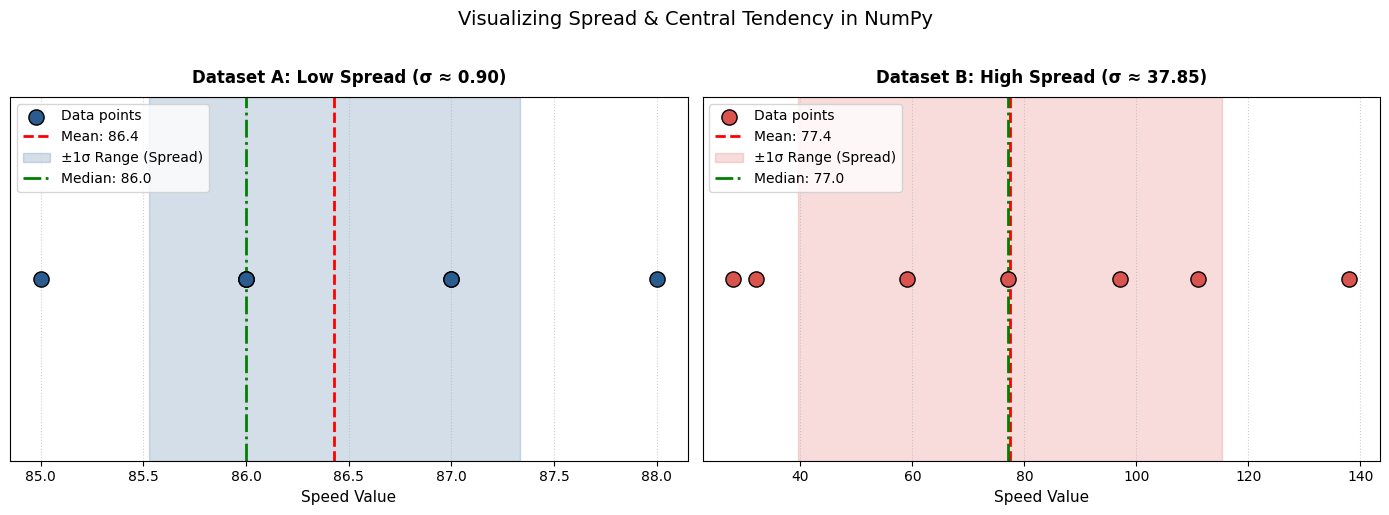

In [2]:
# ==============================================================================
# Statistical Analysis: Mean, Median, Mode, Variance & Standard Deviation
# ==============================================================================

import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. Datasets (Low Spread vs. High Spread from W3Schools)
# ------------------------------------------------------------------------------
speed_low_spread = np.array([86, 87, 88, 86, 87, 85, 86])
speed_high_spread = np.array([32, 111, 138, 28, 59, 77, 97])

def analyze_dataset(name: str, data: np.ndarray):
    print("=" * 60)
    print(f"ANALYSIS: {name}")
    print("=" * 60)
    print(f"Raw data       : {data.tolist()}")
    print(f"Sorted data    : {np.sort(data).tolist()}")
    print(f"Sample size (n): {len(data)}\n")

    # --- Central Tendency ---
    mean_val = np.mean(data)
    median_val = np.median(data)
    mode_res = stats.mode(data, keepdims=False)

    print("--- Central Tendency ---")
    print(f"Mean   (Average)    : {mean_val:.2f}")
    print(f"Median (Middle val) : {median_val:.2f}")
    print(f"Mode   (Most common): {mode_res.mode} (count: {mode_res.count})")

    # --- Dispersion & Spread ---
    # Manual Variance Calculation (Step-by-step demonstration)
    diffs = data - mean_val
    squared_diffs = diffs ** 2
    manual_variance = np.sum(squared_diffs) / len(data)

    # NumPy calculations
    variance_val = np.var(data)       # Population variance (N)
    std_dev_val = np.std(data)        # Population standard deviation

    print("\n--- Dispersion & Variability ---")
    print(f"Manual Variance (Mean of squared differences): {manual_variance:.2f}")
    print(f"NumPy Variance (σ²)                          : {variance_val:.2f}")
    print(f"NumPy Standard Deviation (σ = √variance)     : {std_dev_val:.2f}")

    return {
        "mean": mean_val,
        "median": median_val,
        "mode": mode_res.mode,
        "std": std_dev_val,
        "var": variance_val
    }

# Run numerical calculations
metrics_low = analyze_dataset("Dataset A (Low Spread / Clustered)", speed_low_spread)
print("\n")
metrics_high = analyze_dataset("Dataset B (High Spread / Dispersed)", speed_high_spread)

# ------------------------------------------------------------------------------
# 2. Side-by-Side Visual Comparison in Colab
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

datasets = [
    (axes[0], speed_low_spread, metrics_low, "Dataset A: Low Spread (σ ≈ 0.90)", "#2b5c8f"),
    (axes[1], speed_high_spread, metrics_high, "Dataset B: High Spread (σ ≈ 37.85)", "#d9534f")
]

for ax, data, metrics, title, color in datasets:
    # Plot data points as a strip/jitter plot
    y_coords = np.zeros_like(data)
    ax.scatter(data, y_coords, color=color, s=120, edgecolors="black", zorder=3, label="Data points")

    # Highlight Mean
    ax.axvline(metrics["mean"], color="red", linestyle="--", linewidth=2,
               label=f"Mean: {metrics['mean']:.1f}")

    # Highlight Standard Deviation spread (Mean ± 1σ)
    ax.axvspan(metrics["mean"] - metrics["std"], metrics["mean"] + metrics["std"],
               alpha=0.2, color=color, label=f"±1σ Range (Spread)")

    # Plot Median
    ax.axvline(metrics["median"], color="green", linestyle="-.", linewidth=2,
               label=f"Median: {metrics['median']:.1f}")

    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Speed Value", fontsize=11)
    ax.set_yticks([])
    ax.grid(axis="x", linestyle=":", alpha=0.6)
    ax.legend(loc="upper left")

plt.suptitle("Visualizing Spread & Central Tendency in NumPy", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()